In [54]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.preprocessing import LabelEncoder,MinMaxScaler
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB,BernoulliNB,MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE


#from sklearn.metrics import classification_report,ConfusionMatrixDisplay,accuracy_score
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import pickle

from feature_engine.outliers import Winsorizer
winsor=Winsorizer(capping_method='mad',tail='both',fold=1.5) 

import warnings
warnings.filterwarnings('ignore')

In [55]:
df=pd.read_csv(r"C:\Users\adhil\OneDrive\Desktop\COPD\COPD_prediction_dataset.csv")

In [56]:
df

,Age,Gender,Blood Pressure,Cholesterol,Smoking,Alcohol Consumption,Exercise,BMI,Family History,COPD
0,69,Male,High,High,Yes,No,No,35.671099,No,0
1,32,Male,Low,High,Yes,No,Yes,38.554188,Yes,0
2,89,Female,Normal,High,No,No,Yes,18.932964,Yes,0
3,78,Male,High,High,No,No,Yes,21.806350,Yes,0
4,38,Male,Low,Normal,Yes,Yes,Yes,37.552683,No,0
...,...,...,...,...,...,...,...,...,...,...
995,27,Female,Low,High,No,No,No,31.960176,Yes,0
996,51,Female,High,High,No,Yes,Yes,20.118492,Yes,0
997,72,Female,Normal,High,Yes,No,No,20.916536,Yes,0
998,49,Male,Normal,High,Yes,No,Yes,19.560143,Yes,0


In [57]:
df.head

<bound method NDFrame.head of      Age  Gender Blood Pressure Cholesterol Smoking Alcohol Consumption  \
0     69    Male           High        High     Yes                  No   
1     32    Male            Low        High     Yes                  No   
2     89  Female         Normal        High      No                  No   
3     78    Male           High        High      No                  No   
4     38    Male            Low      Normal     Yes                 Yes   
..   ...     ...            ...         ...     ...                 ...   
995   27  Female            Low        High      No                  No   
996   51  Female           High        High      No                 Yes   
997   72  Female         Normal        High     Yes                  No   
998   49    Male         Normal        High     Yes                  No   
999   67    Male           High      Normal     Yes                  No   

    Exercise        BMI Family History  COPD  
0         No  35.67109

In [58]:
df.tail

<bound method NDFrame.tail of      Age  Gender Blood Pressure Cholesterol Smoking Alcohol Consumption  \
0     69    Male           High        High     Yes                  No   
1     32    Male            Low        High     Yes                  No   
2     89  Female         Normal        High      No                  No   
3     78    Male           High        High      No                  No   
4     38    Male            Low      Normal     Yes                 Yes   
..   ...     ...            ...         ...     ...                 ...   
995   27  Female            Low        High      No                  No   
996   51  Female           High        High      No                 Yes   
997   72  Female         Normal        High     Yes                  No   
998   49    Male         Normal        High     Yes                  No   
999   67    Male           High      Normal     Yes                  No   

    Exercise        BMI Family History  COPD  
0         No  35.67109

In [59]:
df.info

<bound method DataFrame.info of      Age  Gender Blood Pressure Cholesterol Smoking Alcohol Consumption  \
0     69    Male           High        High     Yes                  No   
1     32    Male            Low        High     Yes                  No   
2     89  Female         Normal        High      No                  No   
3     78    Male           High        High      No                  No   
4     38    Male            Low      Normal     Yes                 Yes   
..   ...     ...            ...         ...     ...                 ...   
995   27  Female            Low        High      No                  No   
996   51  Female           High        High      No                 Yes   
997   72  Female         Normal        High     Yes                  No   
998   49    Male         Normal        High     Yes                  No   
999   67    Male           High      Normal     Yes                  No   

    Exercise        BMI Family History  COPD  
0         No  35.671

In [60]:
df.describe()

,Age,BMI,COPD
count,1000.000000,1000.000000,1000.00000
mean,52.881000,29.213037,0.10100
std,20.958915,6.196368,0.30148
min,18.000000,18.504881,0.00000
25%,34.750000,23.924004,0.00000
50%,52.500000,28.892349,0.00000
75%,71.000000,34.663806,0.00000
max,89.000000,39.974048,1.00000


In [61]:
df.shape

(1000, 10)

In [62]:
df.dtypes

Age                      int64
Gender                     str
Blood Pressure             str
Cholesterol                str
Smoking                    str
Alcohol Consumption        str
Exercise                   str
BMI                    float64
Family History             str
COPD                     int64
dtype: object

In [63]:
#data cleaning

In [64]:
df=df.drop_duplicates()

In [65]:
df.isna().sum()

Age                    0
Gender                 0
Blood Pressure         0
Cholesterol            0
Smoking                0
Alcohol Consumption    0
Exercise               0
BMI                    0
Family History         0
COPD                   0
dtype: int64

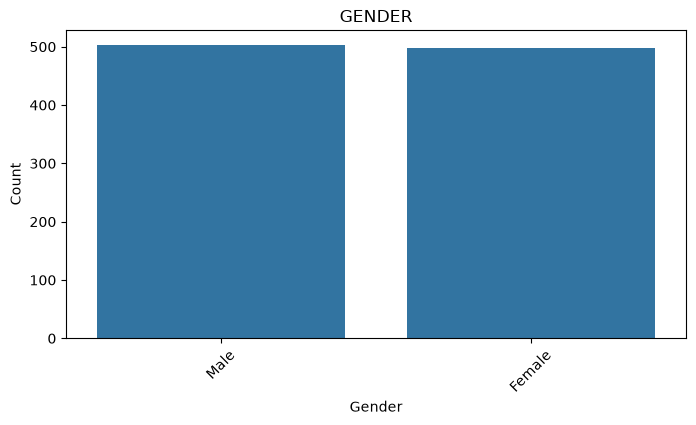

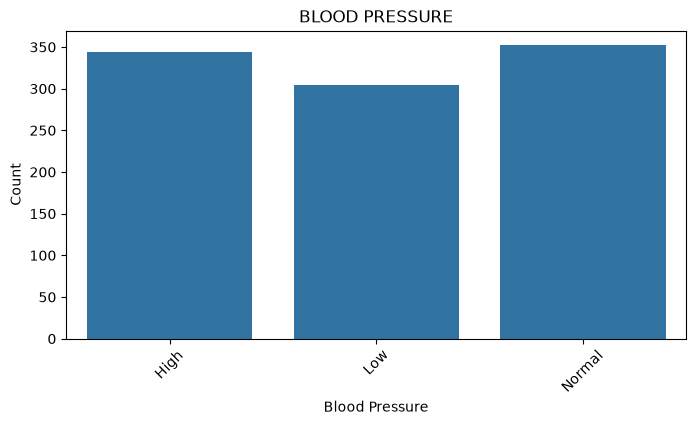

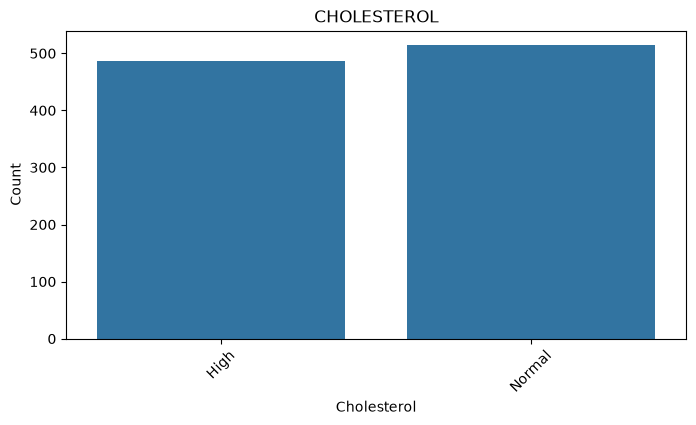

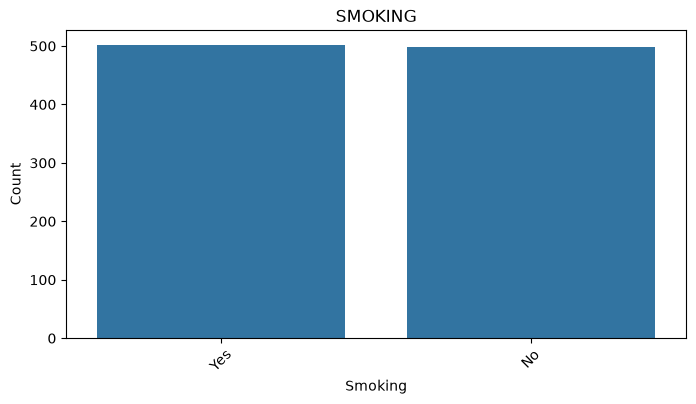

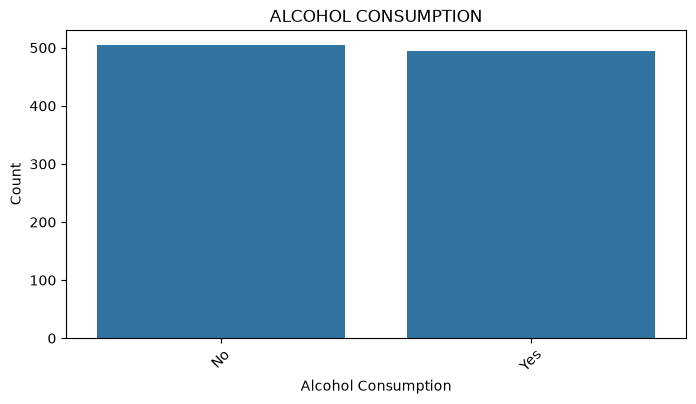

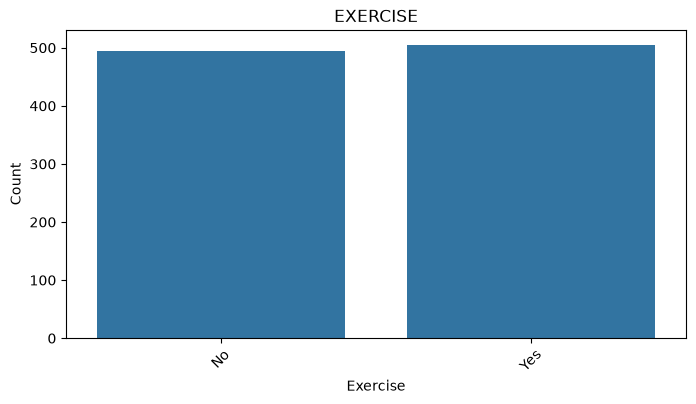

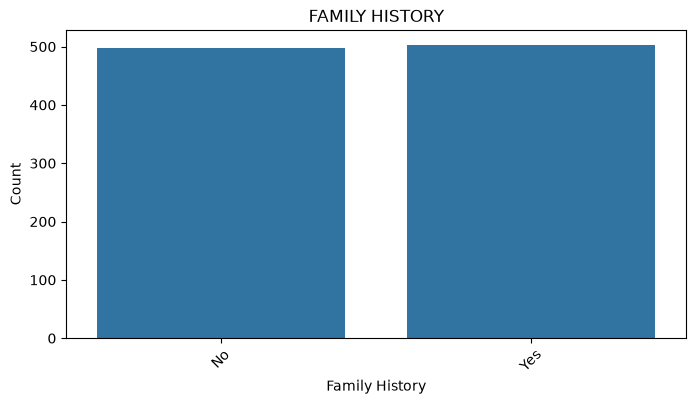

In [66]:
#BARCHART
#selected columns for barchart visualization
selected_columns = ['Gender','Blood Pressure','Cholesterol',
                    'Smoking','Alcohol Consumption','Exercise','Family History']


# Loop through every categorical column in the DataFrame
for column in df[selected_columns]:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=column, data=df)
    plt.title(column.upper())
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()
    

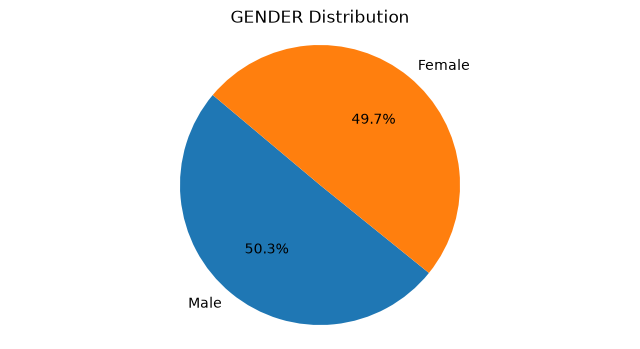

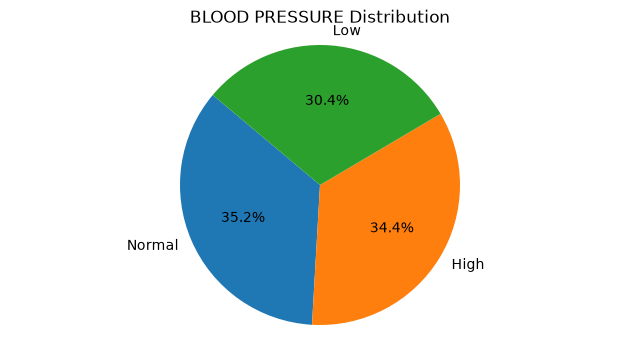

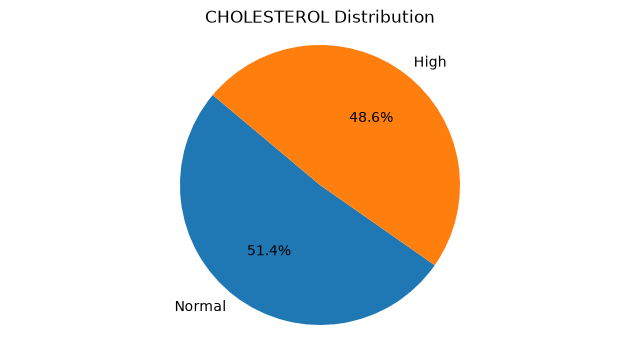

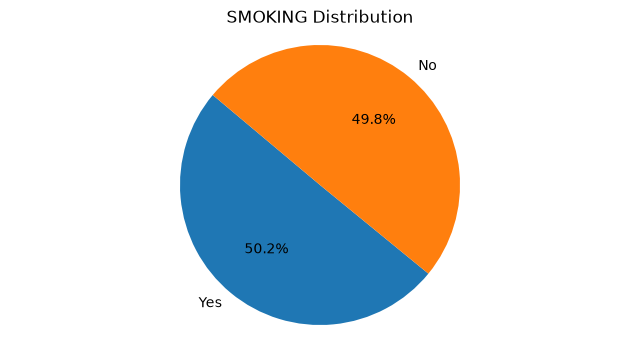

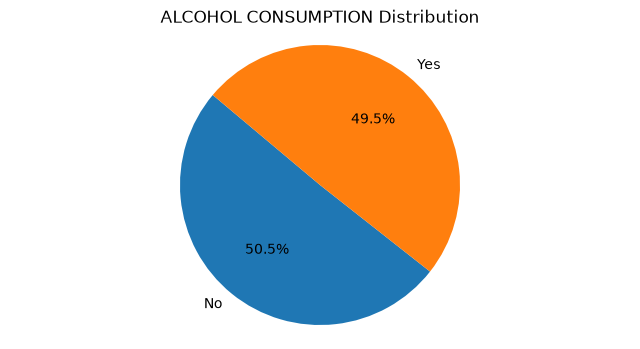

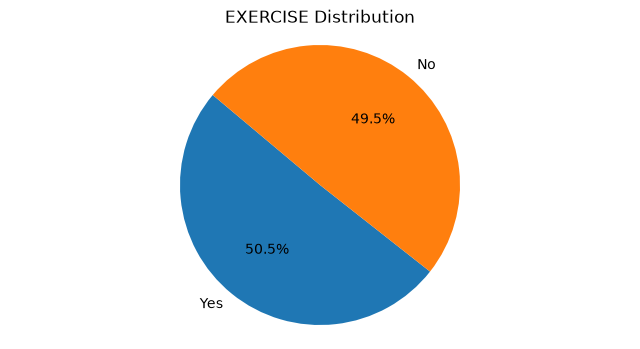

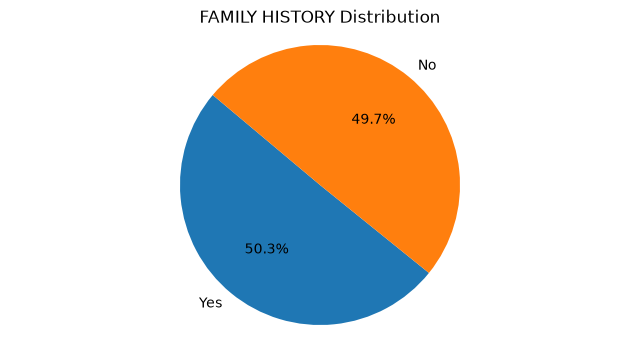

In [67]:
#PIECHART
#selected columns for piechart visualization
selected_columns = ['Gender','Blood Pressure','Cholesterol','Smoking','Alcohol Consumption','Exercise','Family History']

# Loop through every categorical column in the DataFrame
for column in df[selected_columns]:
    plt.figure(figsize=(8, 4))
    plt.pie(
        df[column].value_counts(),
        labels=df[column].value_counts().index,
        autopct='%1.1f%%',
        startangle=140
    )
    plt.title(f'{column.upper()} Distribution')
    plt.axis('equal')  # Equal aspect ratio ensures that pie chart is circular.
    plt.show()

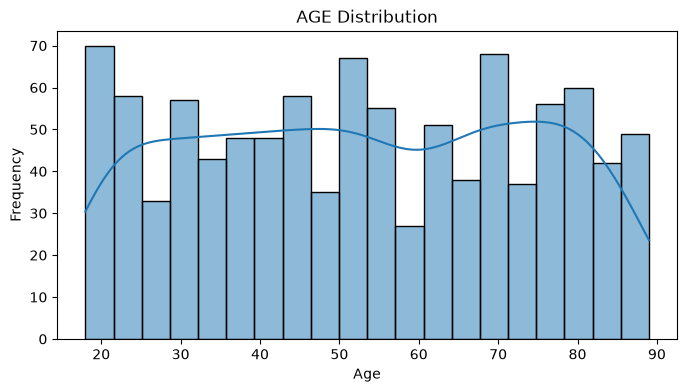

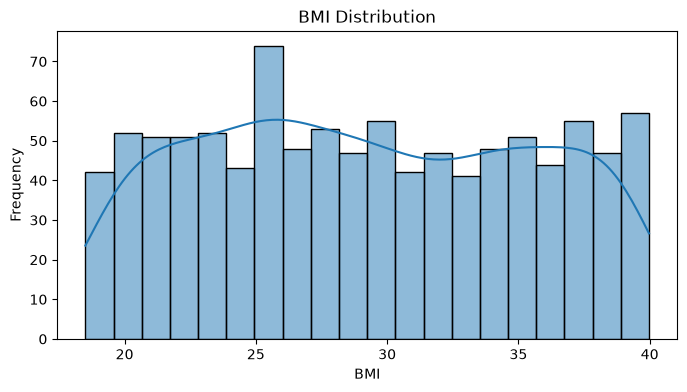

In [68]:
#HISTOGRAM 
#selected columns for histogram visualization
selected_columns = ['Age','BMI']

# Loop through every numerical column in the DataFrame
for column in df[selected_columns]:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[column], bins=20, kde=True)
    plt.title(f'{column.upper()} Distribution')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

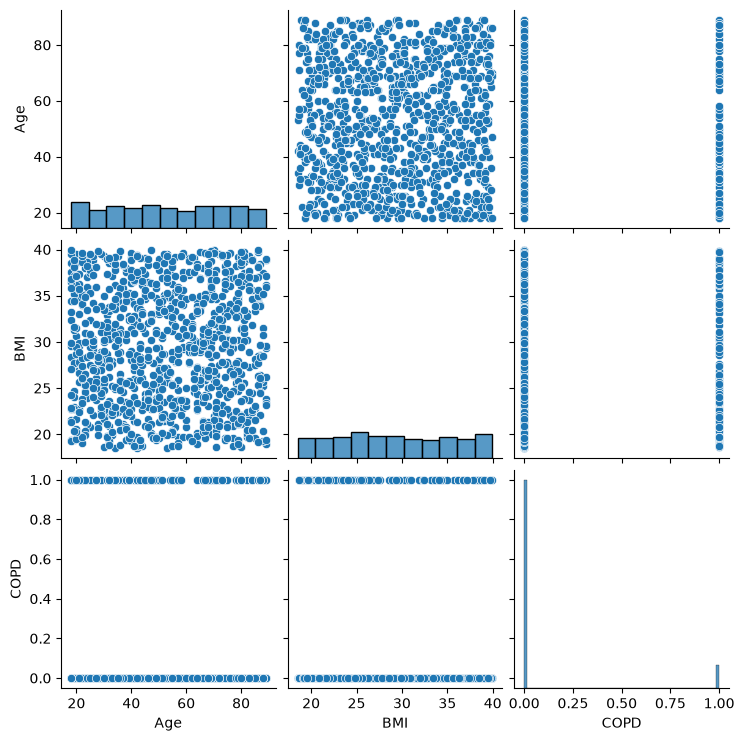

In [69]:
#PAIR PLOT
sns.pairplot(df)

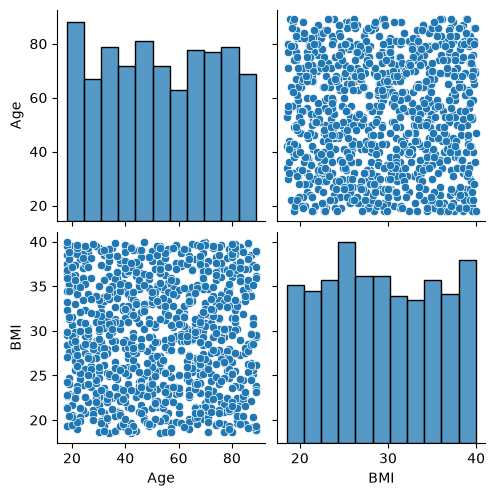

In [70]:
#PAIR PLOT
selected_columns = ['Age','BMI']
sns.pairplot(df[selected_columns])
plt.show()

In [71]:
#Label encoding

In [72]:
from sklearn.preprocessing import LabelEncoder

In [73]:
df['Gender'].unique()
df['Blood Pressure'].unique()
df['Cholesterol'].unique()
df['Smoking'].unique()
df['Alcohol Consumption'].unique()
df['Exercise'].unique()
df['Family History'].unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

In [74]:
# Creating separate encoder
le_Gender=LabelEncoder()
le_Blood_Pressure=LabelEncoder()
le_Cholesterol=LabelEncoder()
le_Smoking=LabelEncoder()
le_Alcohol_consumption=LabelEncoder()
le_Exercise=LabelEncoder()
le_Family_History=LabelEncoder()

df['Gender']=le_Gender.fit_transform(df['Gender'])
df['Blood Pressure']=le_Blood_Pressure.fit_transform(df['Blood Pressure'])
df['Cholesterol']=le_Cholesterol.fit_transform(df['Cholesterol'])
df['Smoking']=le_Smoking.fit_transform(df['Smoking'])
df['Alcohol Consumption']=le_Alcohol_consumption.fit_transform(df['Alcohol Consumption'])
df['Exercise']=le_Exercise.fit_transform(df['Exercise'])
df['Family History']=le_Family_History.fit_transform(df['Family History'])

In [75]:
df['Gender'].unique()
df['Blood Pressure'].unique()
df['Cholesterol'].unique()
df['Smoking'].unique()
df['Alcohol Consumption'].unique()
df['Exercise'].unique()
df['Family History'].unique()

array([0, 1])

<Axes: >

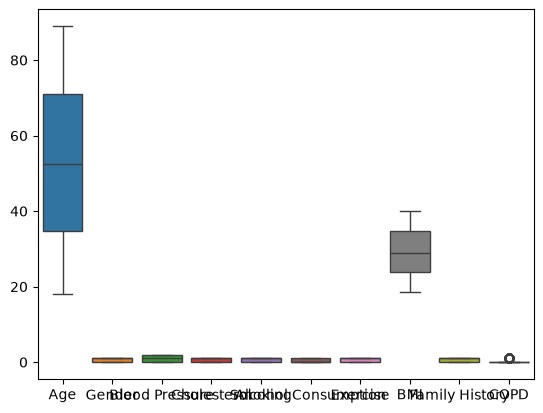

In [76]:
plt.Figure(figsize=(15,5))
sns.boxplot(df)

In [78]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3-Q1

lower_bound = Q1 - 1.5 *IQR
upper_bound = Q3 + 1.5 *IQR

df_capped = df.clip(lower=lower_bound,upper=upper_bound,axis=1)

In [79]:
X = df.drop('COPD', axis=1)
Y = df['COPD']

In [80]:
X

,Age,Gender,Blood Pressure,Cholesterol,Smoking,Alcohol Consumption,Exercise,BMI,Family History
0,69,1,0,0,1,0,0,35.671099,0
1,32,1,1,0,1,0,1,38.554188,1
2,89,0,2,0,0,0,1,18.932964,1
3,78,1,0,0,0,0,1,21.806350,1
4,38,1,1,1,1,1,1,37.552683,0
...,...,...,...,...,...,...,...,...,...
995,27,0,1,0,0,0,0,31.960176,1
996,51,0,0,0,0,1,1,20.118492,1
997,72,0,2,0,1,0,0,20.916536,1
998,49,1,2,0,1,0,1,19.560143,1


In [81]:
Y

0      0
1      0
2      0
3      0
4      0
      ..
995    0
996    0
997    0
998    0
999    1
Name: COPD, Length: 1000, dtype: int64

In [82]:
Y.value_counts()

COPD
0    899
1    101
Name: count, dtype: int64

In [83]:
over=SMOTE(random_state=1)
X,Y=over.fit_resample(X,Y)

In [84]:
m=MinMaxScaler()
X=m.fit_transform(X)


In [85]:
X

array([[0.71830986, 1.        , 0.        , ..., 0.        , 0.79957542,
        0.        ],
       [0.1971831 , 1.        , 0.5       , ..., 1.        , 0.93386516,
        1.        ],
       [1.        , 0.        , 1.        , ..., 1.        , 0.01993941,
        1.        ],
       ...,
       [0.05633803, 0.        , 0.5       , ..., 0.        , 0.12784763,
        0.        ],
       [0.11267606, 0.        , 0.5       , ..., 1.        , 0.35045563,
        0.        ],
       [0.09859155, 0.        , 0.5       , ..., 1.        , 0.22232207,
        1.        ]], shape=(1798, 9))

In [86]:
# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=1)

In [87]:
X_test.shape,X_train.shape

((360, 9), (1438, 9))

In [88]:
Y_test.shape,Y_train.shape

((360,), (1438,))

        KNeighborsClassifier()
****************************************************
accuracy= 81.66666666666667
              precision    recall  f1-score   support

           0       0.83      0.79      0.81       177
           1       0.80      0.85      0.82       183

    accuracy                           0.82       360
   macro avg       0.82      0.82      0.82       360
weighted avg       0.82      0.82      0.82       360



        RandomForestClassifier()
****************************************************
accuracy= 86.38888888888889
              precision    recall  f1-score   support

           0       0.85      0.88      0.86       177
           1       0.88      0.85      0.86       183

    accuracy                           0.86       360
   macro avg       0.86      0.86      0.86       360
weighted avg       0.86      0.86      0.86       360



        DecisionTreeClassifier()
****************************************************
accuracy= 83.33333333333334
  

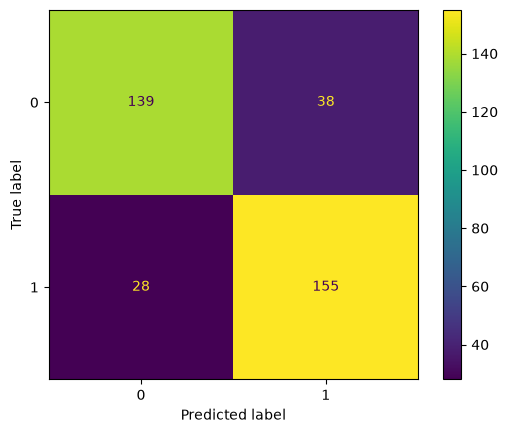

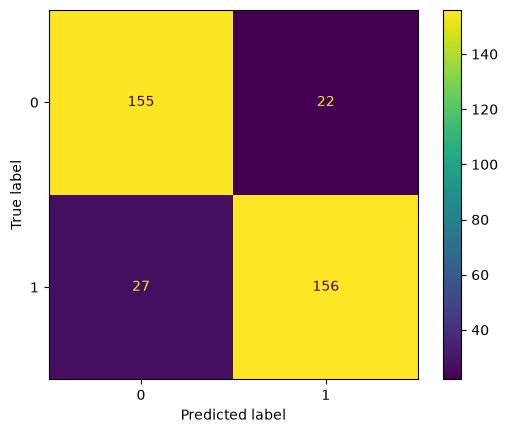

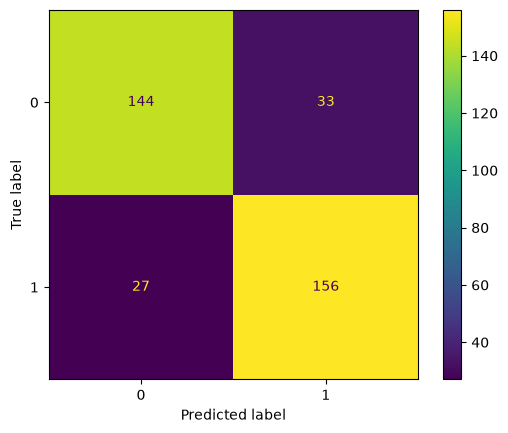

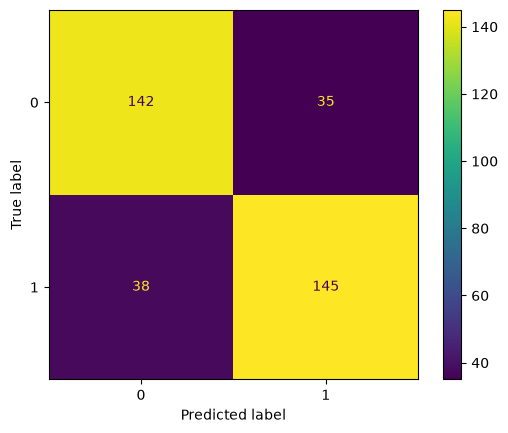

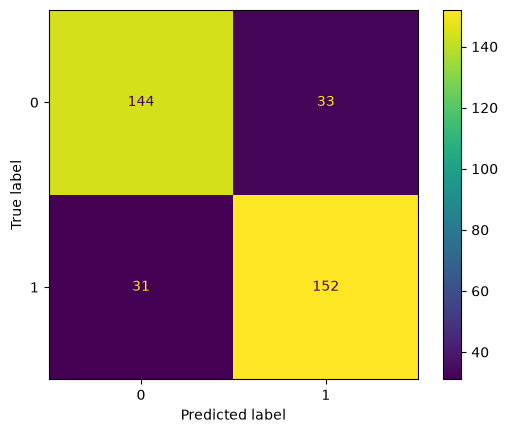

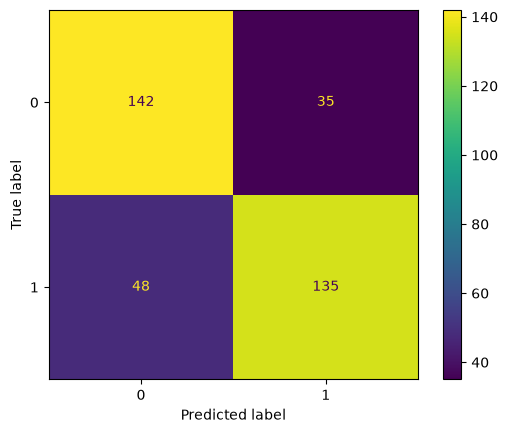

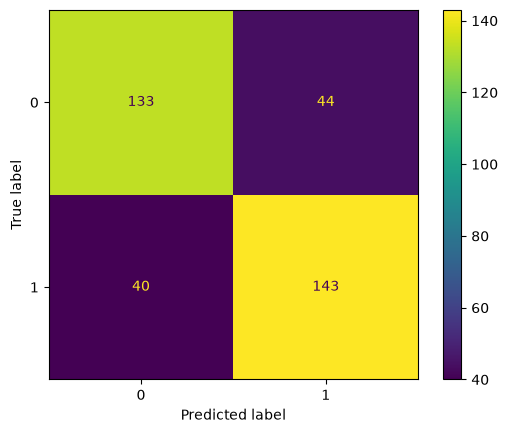

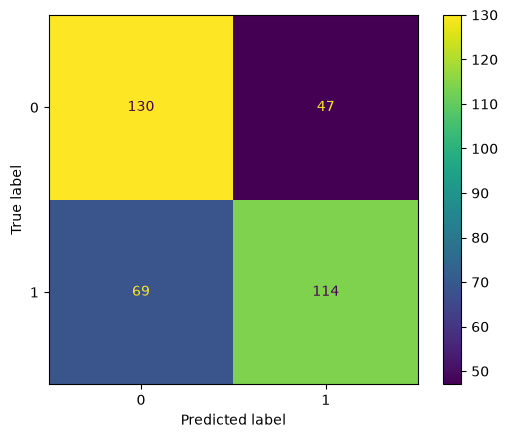

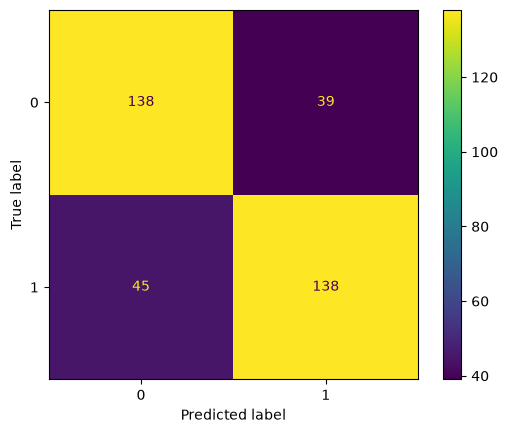

In [89]:
k=KNeighborsClassifier()
r=RandomForestClassifier()
d=DecisionTreeClassifier()
a=AdaBoostClassifier()
s=SVC()
g=GaussianNB()
b=BernoulliNB()
m1=MultinomialNB()
l=LogisticRegression()

model=[k,r,d,a,s,g,b,m1,l]
for i in model:
    print('       ',i  )
    print('****************************************************')
    i.fit(X_train,Y_train)
    Y_Pred=i.predict(X_test)
    print('accuracy=',accuracy_score(Y_test,Y_Pred)*100)
    print(classification_report(Y_test,Y_Pred))
    print(ConfusionMatrixDisplay.from_predictions(Y_test,Y_Pred))
    print()
    print()

In [90]:
from sklearn.model_selection import cross_val_score
import numpy as np

print("Cross validation scores for all models on training data:")
for i in model:
    print("          ",i.__class__.__name__)
    print("*******************************************************")
    # Using cv=3 and n_jobs=-1 for faster execution
    scores=cross_val_score (i, X, Y, cv=3, scoring='accuracy', n_jobs=-1)
    
    print(f"CV Accuracy Scores: {scores}")
    print(f"Mean Accuracy: {np.mean(scores)*100:2f}%\n")

Cross validation scores for all models on training data:
           KNeighborsClassifier
*******************************************************
CV Accuracy Scores: [0.77333333 0.82470785 0.79966611]
Mean Accuracy: 79.923576%

           RandomForestClassifier
*******************************************************
CV Accuracy Scores: [0.825      0.86978297 0.88814691]
Mean Accuracy: 86.097663%

           DecisionTreeClassifier
*******************************************************
CV Accuracy Scores: [0.77333333 0.83639399 0.82971619]
Mean Accuracy: 81.314784%

           AdaBoostClassifier
*******************************************************
CV Accuracy Scores: [0.71166667 0.81469115 0.80467446]
Mean Accuracy: 77.701076%

           SVC
*******************************************************
CV Accuracy Scores: [0.74333333 0.80801336 0.81469115]
Mean Accuracy: 78.867928%

           GaussianNB
*******************************************************
CV Accuracy Scores: [0.7183333

In [91]:
Age=int(input("Enter the Age:"))
Gender=input("Enter your Gender(Male/Female):")
Blood_Pressure=input("Enter blood pressure(High/Normal/Low)?:")
Cholesterol=input("Do you have cholesterol(High/Normal)?:")
Smoking=input("Do you smoke(Yes/no)?:")
Alcohol_consumption=(input("do you consume alcohol(Yes/No)?:"))
Exercise=input("Do you excersise regularly?:")
BMI=float(input("Enter BMI:"))
Family_history=input("Did anyone in your family had COPD(Yes/No)?:")


# Encode categorical columns
Gender_encoded=le_Gender.transform ([Gender])[0]
Blood_Pressure_encoded=le_Blood_Pressure.transform([Blood_Pressure])[0]
Cholesterol_encoded=le_Cholesterol.transform([Cholesterol])[0]
Smoking_encoded=le_Smoking.transform([Smoking])[0]
Alcohol_consumption_encoded=le_Alcohol_consumption.transform([Alcohol_consumption])[0]
Exercise_encoded=le_Exercise.transform([Exercise])[0]
Family_history_encoded=le_Family_History.transform([Family_history])[0]

# Prediction    
y2=r.predict(
    m.transform([[Age,Gender_encoded,Blood_Pressure_encoded,Cholesterol_encoded,Smoking_encoded,Alcohol_consumption_encoded,Exercise_encoded,BMI,Family_history_encoded]]))
y2=r.predict(m.transform([[69,1,0,0,1,0,0,35.671099,0]]))
if y2==0:
    print("You don't have COPD")
else :
    print("You have COPD")

You don't have COPD


In [92]:
pickle.dump(r,open('COPD_Prediction.save','wb'))
pickle.dump(m,open('COPD_scalar.save','wb'))
pickle.dump(le_Gender,open('COPD_Gender.save','wb'))
pickle.dump(le_Blood_Pressure,open('COPD_Bloodpressure.save','wb'))
pickle.dump(le_Cholesterol,open('COPD_Cholesterol.save','wb'))
pickle.dump(le_Smoking,open('COPD_Smoking.save','wb'))
pickle.dump(le_Alcohol_consumption,open('COPD_Alcoholconsumption.save','wb'))
pickle.dump(le_Exercise,open('COPD_Exercise.save','wb'))
pickle.dump(le_Family_History,open('COPD_Familyhistory.save','wb'))